#  This code is to create compare the CCR7 DC populations from Caro et al and compared it to our mreg DC signatures
* Use only the signatures in Caro et al. 2026 Figure 5D (DC subsets)
* Use only the DEG list as the gene lists
* 7 October 2026
* Version 2 - cleaned up the gene list input from the Caro et al. paper Supplementary file 16.xlsx


In [1]:
#load packages I need
import os
import tools
import scanpy as sc
import pandas as pd
#import dandelion as ddl having trouble loading this
from tqdm import tqdm
import matplotlib.pyplot as plt
import scanpy.external as sce
from matplotlib.pyplot import rc_context
import seaborn as sns

In [2]:
from scipy.stats import zscore

In [3]:
import numpy as np

In [4]:
#show current directory 
os.chdir('/scratch/user/uqlbukat/NRAtlas_analysis_2026')
os.getcwd()

'/scratch/user/uqlbukat/NRAtlas_analysis_2026'

In [5]:
os.listdir()

['20250617_AllDC_bbknn.h5ad',
 'NR_code',
 'newDC2annotations.h5ad',
 '20261003_DC2_bbknn_newannots.h5ad',
 'PubData_Heatmap.pdf',
 '.ipynb_checkpoints',
 'data_oc.h5ad',
 'Reference_mDC_Verse.rds',
 'NRclean_clustered2.h5ad',
 'alldc_ocdata.RDS',
 'AllDC_bbknndata.RDS',
 '20250629_DC2_bbknn_clustered2.h5ad',
 'figures',
 'NRclean_Raw_Data.h5ad']

## Import data with the mregDC data
20250617_AllDC_bbknn.h5ad has the DC subset data

In [6]:
# Import renamed DC anndata
data_DC = sc.read_h5ad('/scratch/user/uqlbukat/NRAtlas_analysis_2026/20250617_AllDC_bbknn.h5ad')

In [7]:
data_DC

AnnData object with n_obs × n_vars = 29887 × 1746
    obs: 'nCount_RNA', 'nFeature_RNA', 'sample_type', 'cancer_type', 'patient_id', 'sample_id', 'percent.mt', 'site', 'sample_type_major', 'cancer_subtype', 'integration_id', 'ident', 'dataset_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'S_score', 'G2M_score', 'keep_or_remove', 'leiden', 'celltype', 'leiden_DC', 'leiden_DC_v2', 'exclude_annots', 'leiden_M', 'Technology', 'NR_annotations_simple', 'sample_type_major2', 'cancer_with_H', 'cancer_broadest', 'patient_treatment', 'DC1_sig', 'DC2_sig', 'DC3_sig', 'mregDC_sig'
    var: 'name', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions'

In [9]:
data_mregDC = data_DC[data_DC.obs["NR_annotations_simple"] == "mregDC"]

In [10]:
data_mregDC.obs

,nCount_RNA,nFeature_RNA,sample_type,cancer_type,patient_id,sample_id,percent.mt,site,sample_type_major,cancer_subtype,...,Technology,NR_annotations_simple,sample_type_major2,cancer_with_H,cancer_broadest,patient_treatment,DC1_sig,DC2_sig,DC3_sig,mregDC_sig
GSE215120_AM1_ACTGAGTCAGGCTGAA-1,7117.000000,1505.000000,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,3.259800,skin,primary tumour,Acral Melanoma,...,10x3',mregDC,primary tumour,Acral Melanoma,MEL,Treatment naive,0.159984,-0.054337,-0.048046,0.741240
GSE215120_AM1_ACTGTCCGTCTCTTAT-1,7875.000000,1515.000000,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.930159,skin,primary tumour,Acral Melanoma,...,10x3',mregDC,primary tumour,Acral Melanoma,MEL,Treatment naive,0.153361,-0.025658,0.004267,0.533987
GSE215120_AM1_CCCTCCTGTCCAGTGC-1,11620.000000,2252.000000,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.092943,skin,primary tumour,Acral Melanoma,...,10x3',mregDC,primary tumour,Acral Melanoma,MEL,Treatment naive,0.180735,-0.183050,-0.085568,0.948031
GSE215120_AM1_CTGTGCTAGTCGTACT-1,9150.000000,1721.000000,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.901639,skin,primary tumour,Acral Melanoma,...,10x3',mregDC,primary tumour,Acral Melanoma,MEL,Treatment naive,0.047205,-0.084146,0.004548,0.456303
GSE215120_AM1_GCGAGAACACATAACC-1,21765.000000,3090.000000,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.108890,skin,primary tumour,Acral Melanoma,...,10x3',mregDC,primary tumour,Acral Melanoma,MEL,Treatment naive,0.118400,-0.042104,-0.041547,0.434298
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GSE180661_HGSOC_SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY_CATCCGTGTCTTGAAC,-10.097813,-7.502369,Adnexa,HGSOC,Left Adnexa,SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY,1298.000000,ovary,primary tumour,HGSOC,...,10x3',mregDC,primary tumour,HGSOC,HGSOC,Treatment naive,0.060804,-0.226261,-0.130388,0.167351
GSE180661_HGSOC_SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY_CCCTAACTCCTGGGAC,-10.101074,-7.394361,Adnexa,HGSOC,Left Adnexa,SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY,1226.000000,ovary,primary tumour,HGSOC,...,10x3',mregDC,primary tumour,HGSOC,HGSOC,Treatment naive,0.085570,-0.248361,-0.101698,0.269321
GSE180661_HGSOC_SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY_CCGGTAGTCTATCGTT,-10.058476,-7.589568,Adnexa,HGSOC,Left Adnexa,SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY,2185.000000,ovary,primary tumour,HGSOC,...,10x3',mregDC,primary tumour,HGSOC,HGSOC,Treatment naive,0.040282,-0.205191,-0.179004,0.244367
GSE180661_HGSOC_SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY_TCACGCTTCCGTCACT,-10.033317,-7.518040,Adnexa,HGSOC,Left Adnexa,SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY,1683.000000,ovary,primary tumour,HGSOC,...,10x3',mregDC,primary tumour,HGSOC,HGSOC,Treatment naive,-0.032647,-0.228790,-0.162280,0.293405


Isolate the cDC2 annotated cell subsets to be used 

In [11]:
data_mregDC.var

,name,mt,n_cells_by_counts,mean_counts,log1p_mean_counts,pct_dropout_by_counts,total_counts,log1p_total_counts,n_cells,highly_variable,means,dispersions,dispersions_norm,mean,std
KLHL17,KLHL17,False,8373,0.013762,0.013668,98.657975,8586.0,9.058005,395,True,0.020695,1.765482,0.770236,4.401962e-16,0.104510
HES4,HES4,False,70336,0.254356,0.226623,88.726543,158695.0,11.974746,3383,True,0.270953,1.909886,1.051629,1.396027e-15,0.398112
ISG15,ISG15,False,353813,6.551920,2.021802,43.290838,4087795.0,15.223517,14721,True,1.347276,3.159896,1.899657,9.448861e-15,0.922907
TNFRSF18,TNFRSF18,False,26091,0.103666,0.098637,95.818133,64678.0,11.077192,1987,True,0.157532,2.008652,1.244088,1.514899e-15,0.300775
TNFRSF4,TNFRSF4,False,33923,0.135501,0.127074,94.562820,84540.0,11.344992,2498,True,0.201545,2.022900,1.271854,1.803994e-15,0.342040
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
S100B,S100B,False,70333,0.709755,0.536350,88.727024,442822.0,13.000925,10344,True,1.835553,3.856184,1.949877,8.585140e-15,1.191227
MT-ATP8,MT-ATP8,True,268154,2.990670,1.383959,57.020266,1865903.0,14.439256,13872,True,1.723030,3.719301,2.726181,2.119527e-14,1.099729
MT-ND4L,MT-ND4L,True,459268,6.269149,1.983639,26.388506,3911372.0,15.179399,22006,True,2.483335,3.879209,2.244271,4.651396e-14,1.282896
MT-ND5,MT-ND5,True,544183,12.252872,2.584214,12.778326,7644665.0,15.849519,26296,True,2.578175,3.077011,0.950360,6.913188e-14,0.828537


## Read in the published gene lists from Caro et al
Looking at only the published genes of interest: CCR7 populations

In [13]:
# read in csv file with the Published gene data
gene_list = pd.read_csv("/scratch/user/uqlbukat/caro_CCR7DCtop100degs_81026.csv", low_memory = False)

In [14]:
gene_list

,CCR7_DC,CCR7_cDC2,CCR7_cDC2A,CCR7_DC3,CCR7_cDC1
0,CCL19,CCL22,MMP12,PLA2G2D,DNASE1L3
1,AOC1,MIR155HG,IL7R,CXCL9,TXN
2,FSCN1,SLC7A11,IL4I1,NR1H3,IL12B
3,BIRC3,INHBA,C15orf48,CCL5,CXCL9
4,CCR7,TNFRSF18,SERPINB9,MMP19,BTLA
...,...,...,...,...,...
95,ANXA3,C1orf21,SDC2,PSAP,FXYD5
96,CCDC28B,KDM2B,MTRNR2L8,TBC1D16,LAPTM5
97,RFTN1,IL32,CH17-373J23.1,ADCK3,JAML
98,PPM1K,PSD3,GZMB,LINC00937,YWHAH


In [15]:
gene_list.shape

(100, 5)

In [16]:
print(type(gene_list))

<class 'pandas.core.frame.DataFrame'>


Convert the gene lists so that the genes are in a list and are not strings

In [17]:
gene_dict = {
    col: gene_list[col]
        .dropna()
        .astype(str)
        .str.strip()
        .tolist()
    for col in gene_list.columns
}

## Create a heatmap with the gene lists and the DC data

In [18]:
gene_dict

{'CCR7_DC': ['CCL19',
  'AOC1',
  'FSCN1',
  'BIRC3',
  'CCR7',
  'NCCRP1',
  'TFPI2',
  'LAD1',
  'TUBB2B',
  'CCL22',
  'LAMP3',
  'MGLL',
  'EBI3',
  'LIMCH1',
  'CD200',
  'TREML1',
  'MARCKSL1',
  'BCL2L14',
  'TXN',
  'IL32',
  'SLCO5A1',
  'KIF2A',
  'HMSD',
  'PLA2G16',
  'NMRK1',
  'C10orf10',
  'RP1-28O10.1',
  'LY75',
  'RAB9A',
  'GCSAM',
  'CD274',
  'IDO1',
  'CD70',
  'GADD45A',
  'ACHE',
  'ANXA6',
  'NRP2',
  'POGLUT1',
  'ARHGAP10',
  'UBD',
  'NUB1',
  'SOCS2',
  'TBC1D4',
  'SIAH2',
  'TMEM150C',
  'TSPAN13',
  'ANKRD33B',
  'GRSF1',
  'DUSP5',
  'ADAM12',
  'RAMP1',
  'KDM2B',
  'GPR157',
  'ERICH1',
  'TRAFD1',
  'MARCKS',
  'TNFRSF11B',
  'CRIP1',
  'PDCD1LG2',
  'RAB8B',
  'ST3GAL5',
  'TRIP10',
  'ARAP2',
  'RPS27L',
  'DUSP4',
  'IL15',
  'MAP3K14',
  'DAPP1',
  'H6PD',
  'TBC1D8',
  'NDE1',
  'TMEM176A',
  'TVP23A',
  'CRLF2',
  'PTGIR',
  'CHST7',
  'CERS6',
  'CCL17',
  'MTSS1',
  'TNFAIP2',
  'TRAF1',
  'SYNPO2',
  'TUBA1C',
  'STRIP2',
  'CTD-2020K17.1',


In [19]:
# Loop through each gene set and calculate the scores
for name, genes in gene_dict.items():
    sc.tl.score_genes(data_mregDC, genes, score_name=name)

       'FAM60A'],
      dtype='object')


/home/uqlbukat/miniforge3/envs/scRNA_env/lib/python3.14/site-packages/scanpy/tools/_score_genes.py:163: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[score_name] = pd.Series(


       'RP11-420L9.5', 'RP11-597D13.9', 'C17orf96', 'GUCY1B3', 'FYB', 'TRGV3',
       'TRIM47', 'PRKCDBP', 'PDE6G', 'KIZ', 'RP11-519G16.3', 'ADCK3'],
      dtype='object')
       'RP11-458J1.1', 'ATP5G2', 'GPX1', 'JAML'],
      dtype='object')


## Check the structure of the data

In [20]:
data_mregDC.obs_names.is_unique

True

In [21]:
data_mregDC.obs_names[:5]

Index(['GSE215120_AM1_ACTGAGTCAGGCTGAA-1', 'GSE215120_AM1_ACTGTCCGTCTCTTAT-1',
       'GSE215120_AM1_CCCTCCTGTCCAGTGC-1', 'GSE215120_AM1_CTGTGCTAGTCGTACT-1',
       'GSE215120_AM1_GCGAGAACACATAACC-1'],
      dtype='object')

In [22]:
data_mregDC.obs.shape

(6051, 48)

# Creating z-score heatmap using average gene expression

In [23]:
#Identify our cell subsets of interest
cell_subsets = ['mregDC']

In [24]:
#Published gene lists as a Python dict {signature_name: [genes]}
signatures = gene_dict
signatures

{'CCR7_DC': ['CCL19',
  'AOC1',
  'FSCN1',
  'BIRC3',
  'CCR7',
  'NCCRP1',
  'TFPI2',
  'LAD1',
  'TUBB2B',
  'CCL22',
  'LAMP3',
  'MGLL',
  'EBI3',
  'LIMCH1',
  'CD200',
  'TREML1',
  'MARCKSL1',
  'BCL2L14',
  'TXN',
  'IL32',
  'SLCO5A1',
  'KIF2A',
  'HMSD',
  'PLA2G16',
  'NMRK1',
  'C10orf10',
  'RP1-28O10.1',
  'LY75',
  'RAB9A',
  'GCSAM',
  'CD274',
  'IDO1',
  'CD70',
  'GADD45A',
  'ACHE',
  'ANXA6',
  'NRP2',
  'POGLUT1',
  'ARHGAP10',
  'UBD',
  'NUB1',
  'SOCS2',
  'TBC1D4',
  'SIAH2',
  'TMEM150C',
  'TSPAN13',
  'ANKRD33B',
  'GRSF1',
  'DUSP5',
  'ADAM12',
  'RAMP1',
  'KDM2B',
  'GPR157',
  'ERICH1',
  'TRAFD1',
  'MARCKS',
  'TNFRSF11B',
  'CRIP1',
  'PDCD1LG2',
  'RAB8B',
  'ST3GAL5',
  'TRIP10',
  'ARAP2',
  'RPS27L',
  'DUSP4',
  'IL15',
  'MAP3K14',
  'DAPP1',
  'H6PD',
  'TBC1D8',
  'NDE1',
  'TMEM176A',
  'TVP23A',
  'CRLF2',
  'PTGIR',
  'CHST7',
  'CERS6',
  'CCL17',
  'MTSS1',
  'TNFAIP2',
  'TRAF1',
  'SYNPO2',
  'TUBA1C',
  'STRIP2',
  'CTD-2020K17.1',


In [25]:
data_mregDC.var_names

Index(['KLHL17', 'HES4', 'ISG15', 'TNFRSF18', 'TNFRSF4', 'MORN1', 'ACOT7',
       'ERRFI1', 'SLC2A5', 'GPR157',
       ...
       'COL18A1', 'PCBP3', 'COL6A1', 'COL6A2', 'DIP2A', 'S100B', 'MT-ATP8',
       'MT-ND4L', 'MT-ND5', 'MT-ND6'],
      dtype='object', length=1746)

## Compute average expression per cell subset

In [26]:
# Make a DataFrame of expression: genes x cells
# If X is sparse, toarray() is OK for moderate size; else keep sparse ops
expr = data_mregDC.to_df()  # shape: (n_cells, n_genes)
expr.index = data_mregDC.obs_names
expr.columns = data_mregDC.var_names

In [27]:
# Add subset labels
meta = data_mregDC.obs.copy()
meta["cell_id"] = meta.index

In [28]:
meta

,nCount_RNA,nFeature_RNA,sample_type,cancer_type,patient_id,sample_id,percent.mt,site,sample_type_major,cancer_subtype,...,DC1_sig,DC2_sig,DC3_sig,mregDC_sig,CCR7_DC,CCR7_cDC2,CCR7_cDC2A,CCR7_DC3,CCR7_cDC1,cell_id
GSE215120_AM1_ACTGAGTCAGGCTGAA-1,7117.000000,1505.000000,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,3.259800,skin,primary tumour,Acral Melanoma,...,0.159984,-0.054337,-0.048046,0.741240,0.355671,0.804326,0.735852,0.076420,1.005441,GSE215120_AM1_ACTGAGTCAGGCTGAA-1
GSE215120_AM1_ACTGTCCGTCTCTTAT-1,7875.000000,1515.000000,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.930159,skin,primary tumour,Acral Melanoma,...,0.153361,-0.025658,0.004267,0.533987,0.353255,0.344370,0.205369,0.189847,0.768162,GSE215120_AM1_ACTGTCCGTCTCTTAT-1
GSE215120_AM1_CCCTCCTGTCCAGTGC-1,11620.000000,2252.000000,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.092943,skin,primary tumour,Acral Melanoma,...,0.180735,-0.183050,-0.085568,0.948031,0.557992,1.057972,0.729987,0.345538,1.065836,GSE215120_AM1_CCCTCCTGTCCAGTGC-1
GSE215120_AM1_CTGTGCTAGTCGTACT-1,9150.000000,1721.000000,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,1.901639,skin,primary tumour,Acral Melanoma,...,0.047205,-0.084146,0.004548,0.456303,0.342977,0.649432,0.416484,0.147828,0.864495,GSE215120_AM1_CTGTGCTAGTCGTACT-1
GSE215120_AM1_GCGAGAACACATAACC-1,21765.000000,3090.000000,tumour,Acral Melanoma,AM1,GSE215120_Acral_MEL_AM1,2.108890,skin,primary tumour,Acral Melanoma,...,0.118400,-0.042104,-0.041547,0.434298,-0.055672,0.430711,0.755100,0.009027,0.810639,GSE215120_AM1_GCGAGAACACATAACC-1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
GSE180661_HGSOC_SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY_CATCCGTGTCTTGAAC,-10.097813,-7.502369,Adnexa,HGSOC,Left Adnexa,SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY,1298.000000,ovary,primary tumour,HGSOC,...,0.060804,-0.226261,-0.130388,0.167351,0.193578,0.316126,0.303742,0.150378,0.519020,GSE180661_HGSOC_SPECTRUM-OV-045_S1_CD45P_LEFT_...
GSE180661_HGSOC_SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY_CCCTAACTCCTGGGAC,-10.101074,-7.394361,Adnexa,HGSOC,Left Adnexa,SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY,1226.000000,ovary,primary tumour,HGSOC,...,0.085570,-0.248361,-0.101698,0.269321,0.519910,0.446457,0.228015,0.190556,0.786846,GSE180661_HGSOC_SPECTRUM-OV-045_S1_CD45P_LEFT_...
GSE180661_HGSOC_SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY_CCGGTAGTCTATCGTT,-10.058476,-7.589568,Adnexa,HGSOC,Left Adnexa,SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY,2185.000000,ovary,primary tumour,HGSOC,...,0.040282,-0.205191,-0.179004,0.244367,0.023644,0.184383,0.165487,0.118506,0.464236,GSE180661_HGSOC_SPECTRUM-OV-045_S1_CD45P_LEFT_...
GSE180661_HGSOC_SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY_TCACGCTTCCGTCACT,-10.033317,-7.518040,Adnexa,HGSOC,Left Adnexa,SPECTRUM-OV-045_S1_CD45P_LEFT_OVARY,1683.000000,ovary,primary tumour,HGSOC,...,-0.032647,-0.228790,-0.162280,0.293405,0.273459,0.491007,0.269279,0.135044,0.612202,GSE180661_HGSOC_SPECTRUM-OV-045_S1_CD45P_LEFT_...


In [29]:
# Restrict to relevant subsets
keep_cells = meta["NR_annotations_simple"].isin(cell_subsets)
expr_sub = expr.loc[keep_cells, :]
meta_sub = meta.loc[keep_cells, :]

In [30]:
# Compute mean expression per gene per subset
# groupby on new_subset_heatmap
expr_sub["NR_annotations_simple"] = meta_sub["NR_annotations_simple"].values
mean_expr_by_subset = (
    expr_sub.groupby("NR_annotations_simple")
    .mean()
    .T  # now: genes x subsets
)
mean_expr_by_subset

/scratch/temp/29455616/ipykernel_1023826/1246512703.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  expr_sub.groupby("NR_annotations_simple")


NR_annotations_simple,mregDC
KLHL17,0.081015
HES4,0.083915
ISG15,-0.118979
TNFRSF18,0.163831
TNFRSF4,0.344123
...,...
S100B,-0.312065
MT-ATP8,0.029075
MT-ND4L,0.098137
MT-ND5,-0.044811


In [31]:
#Collapse to signature scores (mean expression of each gene list)

#Create matrix: rows = cell subsets, cols = signatures
subset_names = cell_subsets
sig_names = list(signatures.keys())
sig_names

['CCR7_DC', 'CCR7_cDC2', 'CCR7_cDC2A', 'CCR7_DC3', 'CCR7_cDC1']

In [32]:
subset_names

['mregDC']

In [33]:
sig_mat = pd.DataFrame(
    index=subset_names,
    columns=sig_names,
    dtype=float
)

In [34]:
sig_mat

,CCR7_DC,CCR7_cDC2,CCR7_cDC2A,CCR7_DC3,CCR7_cDC1
mregDC,NaN,NaN,NaN,NaN,NaN


In [35]:
for sig_name, genes in signatures.items():
    # Intersect with genes present in the object
    genes_in_data = list(set(genes).intersection(mean_expr_by_subset.index))
    if len(genes_in_data) == 0:
        print(f"No genes from {sig_name} found in data; skipping.")
        continue
    
    # mean expression of this signature per subset
    # mean_expr_by_subset: genes x subsets
    sig_values = mean_expr_by_subset.loc[genes_in_data].mean(axis=0)
    
    # Fill into sig_mat
    sig_mat.loc[:, sig_name] = sig_values.loc[subset_names].values

In [36]:
sig_mat

,CCR7_DC,CCR7_cDC2,CCR7_cDC2A,CCR7_DC3,CCR7_cDC1
mregDC,0.874859,0.63635,0.13645,0.234471,0.500272


## Z-score and plot heatmap in Python (pheatmap-style)

In [37]:
# Drop any all-NaN columns, if any signatures were skipped
sig_mat_clean = sig_mat.dropna(axis=1, how="all")
sig_mat_clean

,CCR7_DC,CCR7_cDC2,CCR7_cDC2A,CCR7_DC3,CCR7_cDC1
mregDC,0.874859,0.63635,0.13645,0.234471,0.500272


Don't need to run the code below because there is only one row

In [ ]:
# Z-score across subsets for each signature (so you compare cell types per signature)
# axis=0 => z-score down rows; we want per column, so axis=0 with .apply on DataFrame
#sig_z = sig_mat_clean.apply(zscore, axis=0, result_type="broadcast") 

In [57]:
#rename sig_mat to sig_z
sig_z = sig_mat

In [ ]:
#check summary of sig_z to find out upper and lower limits
print(sig_z.describe())

        CCR7_DC  CCR7_cDC2  CCR7_cDC2A  CCR7_DC3  CCR7_cDC1
count  1.000000    1.00000     1.00000  1.000000   1.000000
mean   0.874859    0.63635     0.13645  0.234471   0.500272
std         NaN        NaN         NaN       NaN        NaN
min    0.874859    0.63635     0.13645  0.234471   0.500272
25%    0.874859    0.63635     0.13645  0.234471   0.500272
50%    0.874859    0.63635     0.13645  0.234471   0.500272
75%    0.874859    0.63635     0.13645  0.234471   0.500272
max    0.874859    0.63635     0.13645  0.234471   0.500272


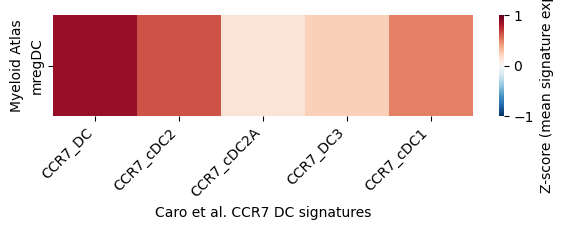

In [ ]:
plt.figure(figsize=(len(sig_z.columns) * 0.4 + 4, len(sig_z.index) * 0.4 + 2))
sns.heatmap(
    sig_z,
    cmap="RdBu_r",
    center=0,
    vmin=-1, #changed from -2
    vmax=1, #changed from 2
    xticklabels=True,
    yticklabels=True,
    cbar_kws={"label": "Z-score (mean signature expression)"}
)
plt.xlabel("Caro et al. CCR7 DC signatures")
plt.ylabel("Myeloid Atlas")
plt.xticks(rotation=45, ha="right")
#plt.yticks(rotation=45)
plt.tight_layout()
# Save the plot as a PDF file
plt.savefig('/scratch/user/uqlbukat/Output/CaroData_mregDConly81026_Heatmap.pdf')
plt.show()

## Overlay Published signatures on our DC2 atlas to see where the cells sit

Visualise the clusters in a UMAP

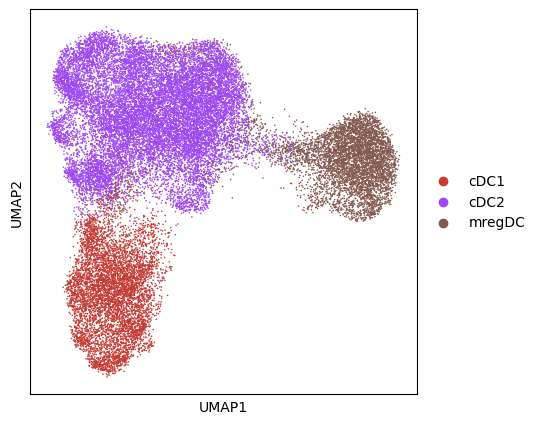

In [54]:
#export high res umap
with plt.rc_context({"figure.figsize": (5, 5)}):
    sc.pl.umap(data_DC, color=["NR_annotations_simple"], size=5, title="")
#plt.savefig('/scratch/user/uqlbukat/Output/DC2Subcluster_umap.pdf')

   # Save the PDF within the context
plt.savefig("/scratch/user/uqlbukat/Output/mregDC_UMAP.pdf", format='pdf')
plt.close() # Closes to free memory

Now visualise the expression of the signatures on the UMAP

In [42]:
gene_dict

{'CCR7_DC': ['CCL19',
  'AOC1',
  'FSCN1',
  'BIRC3',
  'CCR7',
  'NCCRP1',
  'TFPI2',
  'LAD1',
  'TUBB2B',
  'CCL22',
  'LAMP3',
  'MGLL',
  'EBI3',
  'LIMCH1',
  'CD200',
  'TREML1',
  'MARCKSL1',
  'BCL2L14',
  'TXN',
  'IL32',
  'SLCO5A1',
  'KIF2A',
  'HMSD',
  'PLA2G16',
  'NMRK1',
  'C10orf10',
  'RP1-28O10.1',
  'LY75',
  'RAB9A',
  'GCSAM',
  'CD274',
  'IDO1',
  'CD70',
  'GADD45A',
  'ACHE',
  'ANXA6',
  'NRP2',
  'POGLUT1',
  'ARHGAP10',
  'UBD',
  'NUB1',
  'SOCS2',
  'TBC1D4',
  'SIAH2',
  'TMEM150C',
  'TSPAN13',
  'ANKRD33B',
  'GRSF1',
  'DUSP5',
  'ADAM12',
  'RAMP1',
  'KDM2B',
  'GPR157',
  'ERICH1',
  'TRAFD1',
  'MARCKS',
  'TNFRSF11B',
  'CRIP1',
  'PDCD1LG2',
  'RAB8B',
  'ST3GAL5',
  'TRIP10',
  'ARAP2',
  'RPS27L',
  'DUSP4',
  'IL15',
  'MAP3K14',
  'DAPP1',
  'H6PD',
  'TBC1D8',
  'NDE1',
  'TMEM176A',
  'TVP23A',
  'CRLF2',
  'PTGIR',
  'CHST7',
  'CERS6',
  'CCL17',
  'MTSS1',
  'TNFAIP2',
  'TRAF1',
  'SYNPO2',
  'TUBA1C',
  'STRIP2',
  'CTD-2020K17.1',


In [43]:
#mask data and use to calculate gene scores
adata_DC = data_mregDC

In [45]:
adata_DC

AnnData object with n_obs × n_vars = 6051 × 1746
    obs: 'nCount_RNA', 'nFeature_RNA', 'sample_type', 'cancer_type', 'patient_id', 'sample_id', 'percent.mt', 'site', 'sample_type_major', 'cancer_subtype', 'integration_id', 'ident', 'dataset_id', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'S_score', 'G2M_score', 'keep_or_remove', 'leiden', 'celltype', 'leiden_DC', 'leiden_DC_v2', 'exclude_annots', 'leiden_M', 'Technology', 'NR_annotations_simple', 'sample_type_major2', 'cancer_with_H', 'cancer_broadest', 'patient_treatment', 'DC1_sig', 'DC2_sig', 'DC3_sig', 'mregDC_sig', 'CCR7_DC', 'CCR7_cDC2', 'CCR7_cDC2A', 'CCR7_DC3', 'CCR7_cDC1'
    var: 'name', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total

In [46]:
# Loop through each gene set and calculate the scores
for name, genes in gene_dict.items():
    sc.tl.score_genes(adata_DC, genes, score_name=name)

       'FAM60A'],
      dtype='object')
       'RP11-420L9.5', 'RP11-597D13.9', 'C17orf96', 'GUCY1B3', 'FYB', 'TRGV3',
       'TRIM47', 'PRKCDBP', 'PDE6G', 'KIZ', 'RP11-519G16.3', 'ADCK3'],
      dtype='object')
       'RP11-458J1.1', 'ATP5G2', 'GPX1', 'JAML'],
      dtype='object')


In [47]:
colour_vars = gene_dict

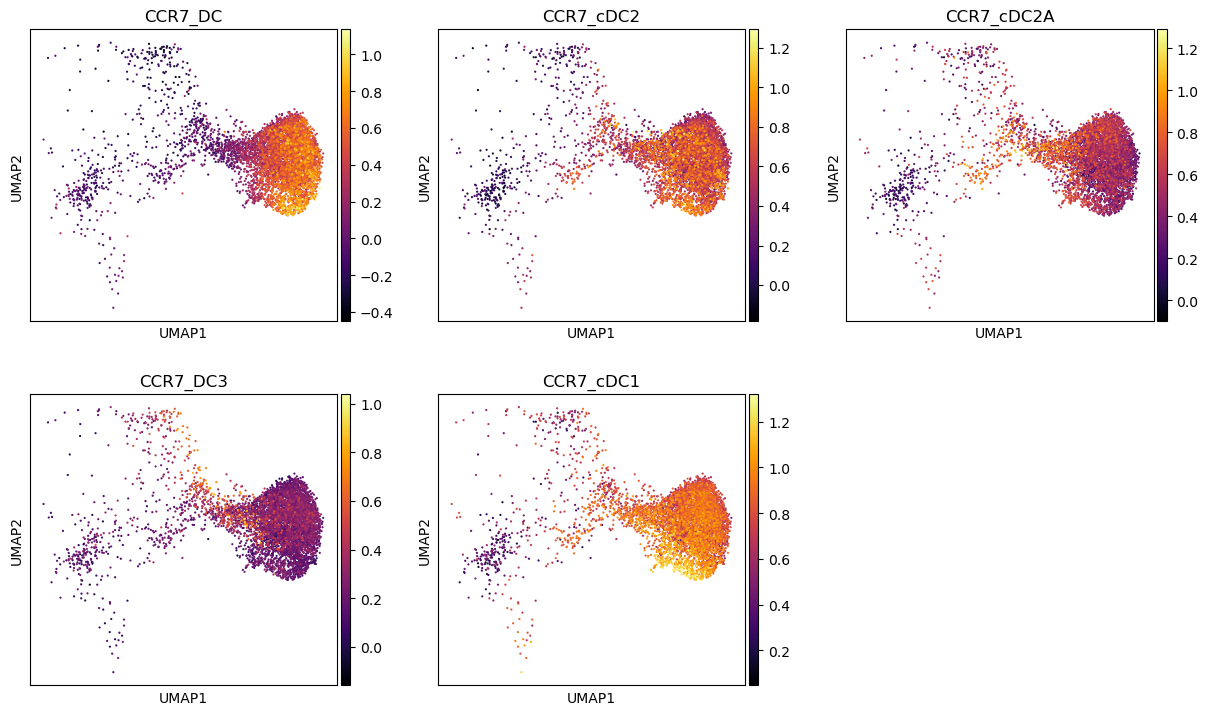

In [48]:
#plotting 
with plt.rc_context({"figure.figsize": (4, 4)}):
    sc.pl.umap(adata_DC, color=colour_vars, ncols=3, size=10,
                cmap='inferno')
#plt.savefig('/scratch/user/uqlbukat/Output/PublishedSigs_DC2SubclusterOverlay.pdf')

In [ ]:
sc.pl.rank_genes_groups_dotplot(data_Brown, groupby="cell_type", key="NR_degs", standard_scale="var", n_genes=10)

In [52]:
colour_vars = ["CCR7_DC","CCR7_cDC2", "CCR7_cDC2A", "CCR7_DC3", "CCR7_cDC1"]

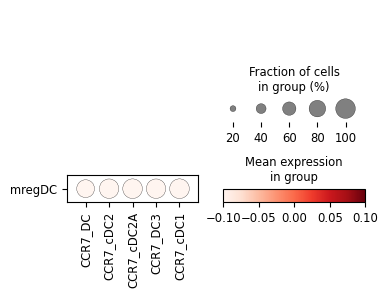

In [62]:
sc.pl.dotplot(data_mregDC, colour_vars, groupby="NR_annotations_simple", standard_scale="var", swap_axes=False)